# Quickmart IPO: Is It Worth Buying at KES 7.50?

**Author:** Siraji Barre Ali | **Source:** Quick Mart PLC Information Memorandum (October 2026) | **Tools:** Python, pandas, matplotlib

## The question
Quickmart, Kenya's second largest supermarket chain, is selling 50% of its shares to the public at **KES 7.50** per share (a **KES 30 billion** valuation). The offer closes on 30 October 2026 and trading on the NSE starts on 12 November 2026.

**This notebook asks:** does the business justify the price, and what would an investor need to believe for KES 7.50 to be a fair price?

## Approach
1. Load five and a half years of financials from the information memorandum
2. Measure growth, margins and cash generation
3. Examine dividends and how much cash has been paid out
4. Value the shares: multiples, a two stage dividend discount model, and scenarios
5. Reverse the model: what growth does KES 7.50 assume?
6. Recommendation

*This is a personal analysis for learning purposes, not investment advice.*

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
print("Libraries loaded.")

Libraries loaded.


## 2. Financial data from the information memorandum
**What this cell does:** enters Quickmart's audited results (FY2021 to FY2025) and the unaudited first half of 2026, in KES millions, straight from the "Selected Historical Financial Information" section. Typing the figures in, rather than scraping the PDF, keeps every number traceable to the source.

In [2]:
periods = ["FY2021", "FY2022", "FY2023", "FY2024", "FY2025", "H1 2026"]

fin = pd.DataFrame({
    "Revenue":           [25680.6, 34781.3, 41215.8, 46707.7, 50427.6, 27266.9],
    "Gross profit":      [5406.2,  7396.2,  8638.2,  10275.5, 11078.3, 6146.1],
    "EBITDA":            [2216.5,  3075.8,  3635.4,  4611.8,  5075.6,  2818.7],
    "Operating profit":  [1097.3,  1641.1,  1979.1,  2966.1,  3450.8,  1948.6],
    "Net finance costs": [828.2,   1239.0,  1333.1,  1321.9,  1284.0,  698.8],
    "Net profit":        [182.6,   275.0,   449.6,   1134.8,  1508.6,  872.8],
    "Operating cash flow": [1983.0, 2492.0, 3961.9, 4207.4, 4827.0, 1379.0],
    "Total equity":      [1399.7,  1386.4,  1236.0,  1194.3,  1055.9,  1928.7],
    "Paid to shareholders": [0.0,  105.9,   782.4,   1176.5,  1647.1,  1100.0],  # H1 2026 = shareholder advance
}, index=periods)

SHARES = 4_000  # million shares after the share split
fin.round(1)

,Revenue,Gross profit,EBITDA,Operating profit,Net finance costs,Net profit,Operating cash flow,Total equity,Paid to shareholders
FY2021,25680.6,5406.2,2216.5,1097.3,828.2,182.6,1983.0,1399.7,0.0
FY2022,34781.3,7396.2,3075.8,1641.1,1239.0,275.0,2492.0,1386.4,105.9
FY2023,41215.8,8638.2,3635.4,1979.1,1333.1,449.6,3961.9,1236.0,782.4
FY2024,46707.7,10275.5,4611.8,2966.1,1321.9,1134.8,4207.4,1194.3,1176.5
FY2025,50427.6,11078.3,5075.6,3450.8,1284.0,1508.6,4827.0,1055.9,1647.1
H1 2026,27266.9,6146.1,2818.7,1948.6,698.8,872.8,1379.0,1928.7,1100.0


## 3. Growth and profitability
**What this cell does:** calculates revenue and profit growth from 2021 to 2025, and the three margins that matter for a supermarket: gross margin (pricing and buying power), EBITDA margin (running costs) and net margin (what is left for shareholders).

In [3]:
full_years = fin.loc["FY2021":"FY2025"]
years = 4
rev_cagr = (full_years["Revenue"].iloc[-1] / full_years["Revenue"].iloc[0]) ** (1 / years) - 1
np_cagr = (full_years["Net profit"].iloc[-1] / full_years["Net profit"].iloc[0]) ** (1 / years) - 1

margins = pd.DataFrame({
    "Gross margin": fin["Gross profit"] / fin["Revenue"],
    "EBITDA margin": fin["EBITDA"] / fin["Revenue"],
    "Net margin": fin["Net profit"] / fin["Revenue"],
    "Revenue growth": fin["Revenue"].pct_change().where(fin.index != "H1 2026"),
})

print(f"Revenue CAGR 2021-2025:    {rev_cagr:.1%}")
print(f"Net profit CAGR 2021-2025: {np_cagr:.1%}")
margins.style.format("{:.1%}", na_rep="")

Revenue CAGR 2021-2025:    18.4%
Net profit CAGR 2021-2025: 69.5%


,Gross margin,EBITDA margin,Net margin,Revenue growth
FY2021,21.1%,8.6%,0.7%,
FY2022,21.3%,8.8%,0.8%,35.4%
FY2023,21.0%,8.8%,1.1%,18.5%
FY2024,22.0%,9.9%,2.4%,13.3%
FY2025,22.0%,10.1%,3.0%,8.0%
H1 2026,22.5%,10.3%,3.2%,


**What this cell does:** draws two charts: revenue and net profit by year, and how the three margins have moved.

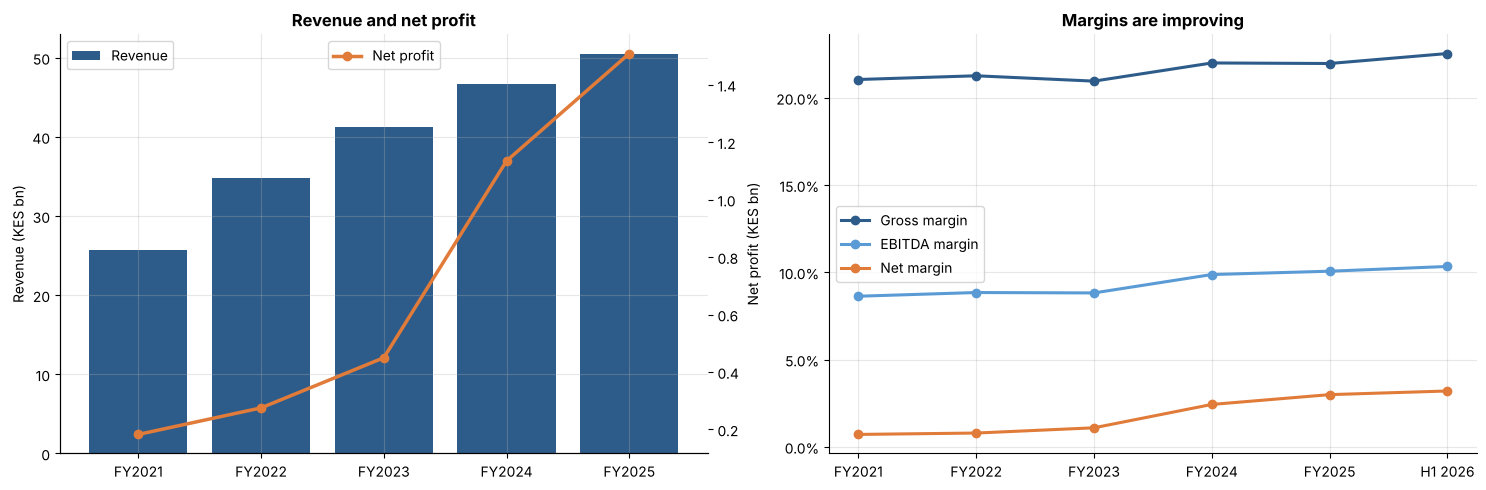

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fy = fin.loc["FY2021":"FY2025"]

ax = axes[0]
ax.bar(fy.index, fy["Revenue"] / 1000, color="#2E5C8A", label="Revenue")
ax.set_ylabel("Revenue (KES bn)")
ax.set_title("Revenue and net profit", fontweight="bold")
ax2 = ax.twinx()
ax2.plot(fy.index, fy["Net profit"] / 1000, color="#E07B39", marker="o", linewidth=2.5, label="Net profit")
ax2.set_ylabel("Net profit (KES bn)")
ax2.grid(False)
ax.legend(loc="upper left"); ax2.legend(loc="upper center")

ax = axes[1]
for col, colour in [("Gross margin", "#2E5C8A"), ("EBITDA margin", "#5B9BD5"), ("Net margin", "#E07B39")]:
    ax.plot(margins.index, margins[col], marker="o", linewidth=2.2, label=col, color=colour)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Margins are improving", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Dividends and cash paid out
**What this cell does:** compares what Quickmart paid its owner each period with the profit it earned (the payout ratio), and tracks shareholders' equity. A payout above 100% means more cash went out than the business earned that year.

In [5]:
payout = pd.DataFrame({
    "Net profit": fin["Net profit"],
    "Paid to shareholders": fin["Paid to shareholders"],
    "Payout ratio": fin["Paid to shareholders"] / fin["Net profit"],
    "Total equity": fin["Total equity"],
})
display(payout.style.format({"Net profit": "{:,.0f}", "Paid to shareholders": "{:,.0f}",
                             "Payout ratio": "{:.0%}", "Total equity": "{:,.0f}"}))

paid_since_2023 = fin.loc["FY2023":"H1 2026", "Paid to shareholders"].sum()
earned_since_2023 = fin.loc["FY2023":"H1 2026", "Net profit"].sum()
print(f"FY2023 to H1 2026: earned KES {earned_since_2023:,.0f}m, paid out KES {paid_since_2023:,.0f}m "
      f"({paid_since_2023 / earned_since_2023:.0%} of profit)")

,Net profit,Paid to shareholders,Payout ratio,Total equity
FY2021,183,0,0%,"1,400"
FY2022,275,106,39%,"1,386"
FY2023,450,782,174%,"1,236"
FY2024,"1,135","1,176",104%,"1,194"
FY2025,"1,509","1,647",109%,"1,056"
H1 2026,873,"1,100",126%,"1,929"


FY2023 to H1 2026: earned KES 3,966m, paid out KES 4,706m (119% of profit)


## 5. Valuation at the offer price
**What this cell does:** works out what investors pay at KES 7.50 on different measures of profit, the dividend yield, and compares the yield with the risk free 91 day Treasury bill. The FY2026 forecasts and net debt come from the offer statistics in the memorandum.

In [6]:
PRICE = 7.50
market_cap = PRICE * SHARES                     # KES millions
net_debt = 7_272.7                               # incl. lease liabilities, 30 June 2026
fc_net_profit, fc_adj_net_profit = 2_102.8, 2_317.2   # FY2026 forecasts
fc_adj_ebitda, fc_dividend = 6_585.2, 2_000.0
TBILL_91 = 0.0876                                # CBK 91 day rate, October 2026

valuation = pd.Series({
    "Market capitalisation (KES m)": market_cap,
    "P/E on FY2025 actual profit": market_cap / fin.loc["FY2025", "Net profit"],
    "P/E on H1 2026 profit x 2": market_cap / (2 * fin.loc["H1 2026", "Net profit"]),
    "P/E on FY2026 forecast (reported)": market_cap / fc_net_profit,
    "P/E on FY2026 forecast (adjusted)": market_cap / fc_adj_net_profit,
    "EV / adjusted EBITDA FY2026": (market_cap + net_debt) / fc_adj_ebitda,
    "Price to book (June 2026)": market_cap / fin.loc["H1 2026", "Total equity"],
    "Forecast dividend per share (KES)": fc_dividend / SHARES,
    "Forecast dividend yield": fc_dividend / market_cap,
    "Forecast payout ratio": fc_dividend / fc_net_profit,
    "Profit growth needed in FY2026": fc_net_profit / fin.loc["FY2025", "Net profit"] - 1,
})
pct_rows = ["Forecast dividend yield", "Forecast payout ratio", "Profit growth needed in FY2026"]
print(valuation.apply(lambda v: f"{v:.1%}").where(valuation.index.isin(pct_rows),
                      valuation.apply(lambda v: f"{v:,.2f}")).to_string())
print(f"\nDividend yield {fc_dividend / market_cap:.1%} vs 91 day T-bill {TBILL_91:.2%}: "
      f"{'below' if fc_dividend / market_cap < TBILL_91 else 'above'} the risk free rate")

Market capitalisation (KES m)        30,000.00
P/E on FY2025 actual profit              19.89
P/E on H1 2026 profit x 2                17.19
P/E on FY2026 forecast (reported)        14.27
P/E on FY2026 forecast (adjusted)        12.95
EV / adjusted EBITDA FY2026               5.66
Price to book (June 2026)                15.55
Forecast dividend per share (KES)         0.50
Forecast dividend yield                   6.7%
Forecast payout ratio                    95.1%
Profit growth needed in FY2026           39.4%

Dividend yield 6.7% vs 91 day T-bill 8.76%: below the risk free rate


## 6. Two stage dividend discount model
**What this cell does:** values each share as the present value of all future dividends. Dividends start at the forecast KES 0.50, grow fast for five years, then settle at a long run rate. The required return uses CAPM, with the same risk free rate and equity risk premium as my Safaricom valuation.

**Key assumptions (change them and rerun):**
* Risk free rate 11.3% (Kenya 10 year bond), equity risk premium 6.5%
* Beta 0.8: grocery retail is defensive, so slightly less risky than the market
* Because Quickmart plans to pay out about 80% to 95% of profit, dividend growth is assumed to track profit growth

In [7]:
RF, ERP, BETA = 0.113, 0.065, 0.80
KE = RF + BETA * ERP
D1 = fc_dividend / SHARES

def ddm_two_stage(d1, g_high, years, g_terminal, ke):
    """Present value of dividends: fast growth for `years`, then constant growth forever."""
    value, dividend = 0.0, d1
    for t in range(1, years + 1):
        value += dividend / (1 + ke) ** t
        if t < years:
            dividend *= 1 + g_high
    terminal = dividend * (1 + g_terminal) / (ke - g_terminal)
    return value + terminal / (1 + ke) ** years

scenarios = pd.DataFrame({
    "Dividend growth, years 1 to 5": [0.05, 0.12, 0.18],
    "Long run growth": [0.05, 0.06, 0.07],
    "Story": ["Growth slows to inflation; Naivas and Carrefour compete hard",
              "Steady store rollout and margin gains continue",
              "Repeats the 2021 to 2025 pace for five more years"],
}, index=["Bear", "Base", "Bull"])
scenarios["Fair value (KES)"] = [ddm_two_stage(D1, g, 5, gt, KE)
                                 for g, gt in zip(scenarios.iloc[:, 0], scenarios.iloc[:, 1])]
scenarios["vs KES 7.50"] = scenarios["Fair value (KES)"] / PRICE - 1

print(f"Required return (CAPM): {KE:.1%}")
scenarios.style.format({"Dividend growth, years 1 to 5": "{:.0%}", "Long run growth": "{:.0%}",
                        "Fair value (KES)": "{:.2f}", "vs KES 7.50": "{:+.0%}"})

Required return (CAPM): 16.5%


,"Dividend growth, years 1 to 5",Long run growth,Story,Fair value (KES),vs KES 7.50
Bear,5%,5%,Growth slows to inflation; Naivas and Carrefour compete hard,4.35,-42%
Base,12%,6%,Steady store rollout and margin gains continue,5.69,-24%
Bull,18%,7%,Repeats the 2021 to 2025 pace for five more years,7.29,-3%


## 7. Sensitivity: how fair value changes with the assumptions
**What this cell does:** recalculates fair value for a range of required returns and five year growth rates (long run growth held at 6%), so you can see which combinations justify KES 7.50. Cells above the offer price are shaded green.

In [8]:
ke_range = [0.140, 0.150, 0.165, 0.180]
g_range = [0.06, 0.09, 0.12, 0.15, 0.18]

grid = pd.DataFrame([[ddm_two_stage(D1, g, 5, 0.06, k) for g in g_range] for k in ke_range],
                    index=[f"Ke {k:.1%}" for k in ke_range],
                    columns=[f"Growth {g:.0%}" for g in g_range])

grid.style.format("{:.2f}").map(lambda v: "background-color: #C6EFCE" if v >= PRICE
                                else "background-color: #FFC7CE")

,Growth 6%,Growth 9%,Growth 12%,Growth 15%,Growth 18%
Ke 14.0%,6.25,6.87,7.53,8.25,9.02
Ke 15.0%,5.56,6.09,6.67,7.29,7.97
Ke 16.5%,4.76,5.21,5.69,6.21,6.76
Ke 18.0%,4.17,4.54,4.95,5.39,5.86


## 8. Reverse the model: what does KES 7.50 assume?
**What this cell does:** instead of choosing growth and calculating a price, it starts from the KES 7.50 price and solves for the five year dividend growth rate that makes the model equal the offer price.

In [9]:
def implied_growth(price, ke, g_terminal=0.06, lo=-0.05, hi=0.60):
    for _ in range(100):                          # bisection search
        mid = (lo + hi) / 2
        if ddm_two_stage(D1, mid, 5, g_terminal, ke) < price:
            lo = mid
        else:
            hi = mid
    return mid

for k in ke_range:
    print(f"Required return {k:.1%}: KES 7.50 needs dividends to grow {implied_growth(PRICE, k):.1%} a year for 5 years")

Required return 14.0%: KES 7.50 needs dividends to grow 11.9% a year for 5 years
Required return 15.0%: KES 7.50 needs dividends to grow 15.9% a year for 5 years
Required return 16.5%: KES 7.50 needs dividends to grow 21.7% a year for 5 years
Required return 18.0%: KES 7.50 needs dividends to grow 27.1% a year for 5 years


## 9. Recommendation

**Rating: NEUTRAL. A good business, priced for strong growth.**

| | |
|---|---|
| Offer price | KES 7.50 |
| Base case fair value | about **KES 5.70** (roughly 24% below the offer price) |
| Fair value range | about KES 4.35 (bear) to KES 7.30 (bull) |

**What is attractive**
* Revenue grew about 18% a year from 2021 to 2025, and net profit grew more than 8x
* Margins have improved every year, and the business converts profit into cash
* Kenya's number two supermarket, with almost no bank debt

**Why the price is not cheap**
* On profit actually earned, KES 7.50 is about 17 to 20 times earnings; the headline 12.9x depends on an adjusted forecast that needs profit to rise 39% in 2026
* Even the bull case falls slightly below KES 7.50 at a 16.5% required return; the price only works with a lower required return and growth near the 2021 to 2025 pace
* The 6.7% dividend yield is below the 91 day T-bill, and needs about 95% of forecast profit to be paid out
* The seller is cashing out: the company receives none of the KES 15 billion, payouts have exceeded profit since 2023, and Adenia can sell its remaining 50% after 24 months

**What would change the view**
* A share price below about KES 6 after listing
* FY2026 results confirming the forecast profit jump
* Evidence that store growth can continue while paying out most of profit

**Limitations:** based only on the information memorandum and my own assumptions (beta, risk premium, growth). Results are sensitive to the required return, as section 7 shows.

*This is a personal analysis for learning purposes, not investment advice. Speak to a licensed stockbroker or financial adviser before investing.*